In [1]:
# GitHubからリポジトリをクローン（URLをご自身のものに書き換えてください）
!git clone https://github.com/sho441/Mohs-hardness-prediction

# プロジェクトのフォルダに移動
import os
os.chdir('/content/Mohs-hardness-prediction')

Cloning into 'Mohs-hardness-prediction'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (112/112), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 112 (delta 54), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (112/112), 683.76 KiB | 5.47 MiB/s, done.
Resolving deltas: 100% (54/54), done.


In [2]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 環境構築（必要な外部ライブラリのインストール）
# Google Colab環境で実行する場合の依存パッケージを一括インストール
!pip install optuna catboost xgboost scikit-learn pandas numpy matplotlib seaborn

# グラフスタイル設定
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

# --- 確実にプロジェクトルートへ移動・sys.pathに追加 ---
# 現在のノートブックの位置から親フォルダ（Mohs-hardness-prediction）をプロジェクトルートとする
current_dir = Path().resolve()
if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# カレントディレクトリ自体をプロジェクトルートに変更
os.chdir(project_root)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"カレントディレクトリ: {os.getcwd()}")
print(f"sys.path[0]: {sys.path[0]}")

# --- モジュールのインポート確認 ---
try:
    from src.config import TRAIN_PATH, TEST_PATH, RANDOM_STATE, N_SPLITS
    from src.features import preprocess_data
    from src.models import get_models
    print("✨ すべてのモジュール（src.*）が正常にインポートされました！")
except ModuleNotFoundError as e:
    print(f"⚠️ インポートエラー: {e}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 56.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [catboost]
カレントディレクトリ: /content/Mohs-hardness-prediction
sys.path[0]: /content/Mohs-hardness-prediction
✨ すべてのモジュール（src.*）が正常にインポートされました！


train_df shape: (10407, 13)
test_df shape: (6939, 12)
ターゲットカラム名: Hardness


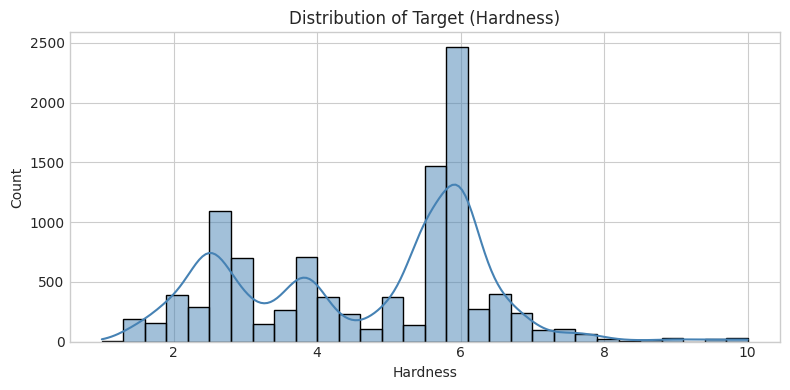

In [3]:
# データの読み込み
train_df = pd.read_csv(
    TRAIN_PATH
)
test_df = pd.read_csv(TEST_PATH)

print(
    f"train_df shape: "
    f"{train_df.shape}"
)
print(
    f"test_df shape: "
    f"{test_df.shape}"
)

# 目的変数（モース硬度: Hardness 等）の確認
target_col = (
    "Hardness"
    if "Hardness"
    in train_df.columns
    else train_df.columns[-1]
)
print(
    f"ターゲットカラム名: "
    f"{target_col}"
)

# 分布の可視化
plt.figure(
    figsize=(8, 4)
)
sns.histplot(
    train_df[target_col],
    kde=True,
    bins=30,
    color="steelblue",
)
plt.title(
    "Distribution of Target "
    f"({target_col})"
)
plt.xlabel(target_col)
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [4]:
# 特徴量とターゲットの分離
y = train_df[target_col]
X = train_df.drop(
    columns=[target_col]
)

# features.py の preprocess_data を実行
print(
    "前処理および特徴量"
    "エンジニアリングを実行中..."
)
X_processed, test_processed = (
    preprocess_data(X, test_df)
)

print(
    "前処理後の特徴量数: "
    f"{X_processed.shape[1]}"
)
print(
    "生成された特徴量の先頭5件:"
)
display(
    X_processed.head()
)

前処理および特徴量エンジニアリングを実行中...
前処理後の特徴量数: 19
生成された特徴量の先頭5件:


,id,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average,comp_mean,comp_std,comp_max,comp_min,comp_sum,interaction_ratio,interaction_product
0,0,100.0,0.841611,10.0,4.8,20.612526,11.08810,2.766,1.732,0.860,0.496070,0.91457,14.010080,29.197496,100.0,0.496070,154.110877,118.819599,84.161100
1,1,100.0,7.558488,10.0,4.8,20.298893,12.04083,2.755,1.631,0.910,0.492719,0.71760,14.654957,28.959606,100.0,0.492719,161.204530,13.230158,755.848800
2,2,76.0,8.885992,15.6,5.6,33.739258,12.08630,2.828,1.788,0.864,0.481478,1.50633,14.489033,22.625840,76.0,0.481478,159.379358,8.552786,675.335392
3,3,100.0,8.795296,10.0,4.8,20.213349,10.94850,2.648,1.626,0.936,0.489272,0.78937,14.658708,28.942332,100.0,0.489272,161.245787,11.369713,879.529600
4,4,116.0,9.577996,11.6,4.8,24.988133,11.82448,2.766,1.682,0.896,0.492736,1.86481,16.953832,33.649382,116.0,0.492736,186.492155,12.111092,1111.047536


In [5]:
# 複数モデルの辞書を取得
models = get_models()
print(
    "利用可能なモデル一覧:"
)
for name in models.keys():
    print(f" - {name}")

# サンプルとしてLightGBMが正常にインスタンス化できるか確認
lgb_model = models["LightGBM"]
print(
    f"\n確認成功: {lgb_model}"
)

利用可能なモデル一覧:
 - Ridge
 - RandomForest
 - LightGBM
 - XGBoost
 - CatBoost

確認成功: LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, metric='rmse',
              n_estimators=1000, objective='regression', random_state=42,
              subsample=0.8, verbose=-1)


特徴量とターゲットの関係性を分析中...


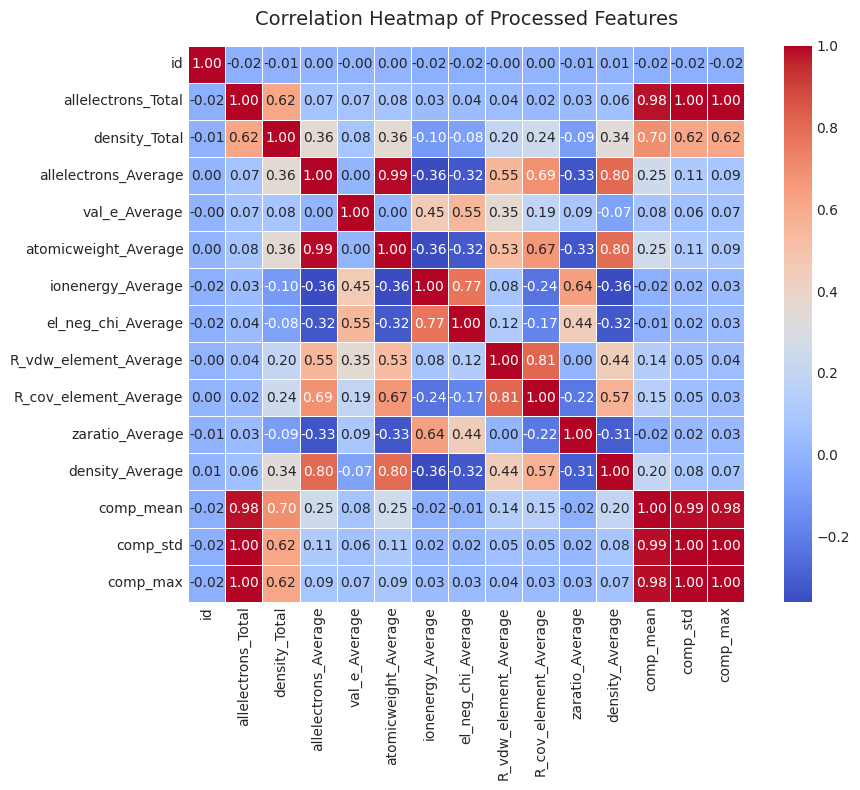

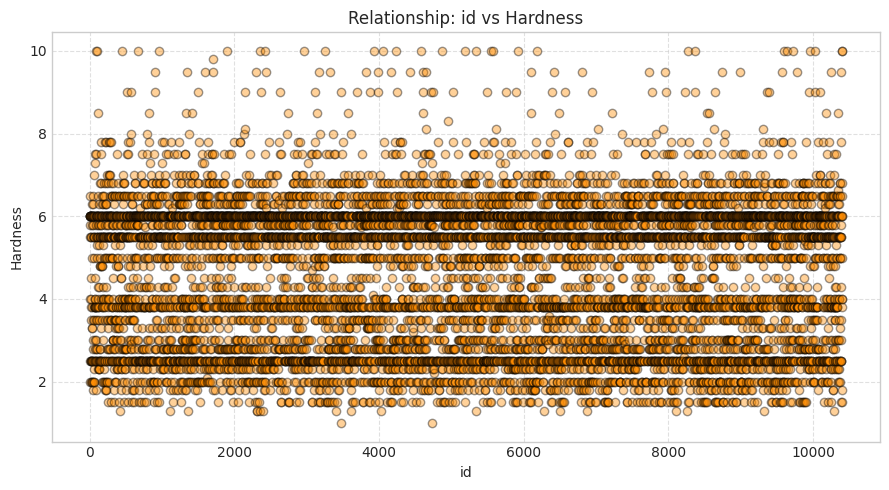

EDAの可視化が正常に完了しました。


In [6]:
print("特徴量とターゲットの関係性を分析中...")

# 1. 目的変数と主要な数値特徴量との相関行列ヒートマップ
plt.figure(figsize=(10, 8))
numeric_cols = X_processed.select_dtypes(
    include=[np.number]
).columns

# 視認性を高めるため、ターゲットを含めた上位の相関または主要特徴量を抜粋
if target_col in train_df.columns:
    temp_df = X_processed.copy()
    temp_df[target_col] = y
    corr_matrix = temp_df[
        numeric_cols[:15]
    ].corr()  # 多すぎると見づらいため主要なものを抽出
else:
    corr_matrix = X_processed[
        numeric_cols[:15]
    ].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True,
    linewidths=0.5,
)
plt.title(
    "Correlation Heatmap of "
    "Processed Features",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

# 2. 生成された特徴量（例: 統計量や非線形特徴量）と硬度の関係性散布図
plt.figure(figsize=(9, 5))
sample_feature = X_processed.columns[0]  # 生成された先頭の特徴量
plt.scatter(
    X_processed[sample_feature],
    y,
    alpha=0.4,
    color="darkorange",
    edgecolors="k",
)
plt.title(
    f"Relationship: {sample_feature} "
    f"vs {target_col}",
    fontsize=12,
)
plt.xlabel(
    sample_feature, fontsize=10
)
plt.ylabel(
    target_col, fontsize=10
)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print(
    "EDAの可視化が正常に完了しました。"
)